<a href="https://colab.research.google.com/github/haninsocialmedia1-maker/HANIN-ABTEST-PROJECT/blob/main/Copy_of_%D9%86%D8%B3%D8%AE%D8%A9_%D9%82%D8%AF%D9%8A%D9%85%D8%A9_2_%D9%84%D8%A7_%D8%AA%D9%8F%D8%B3%D8%AA%D8%AE%D8%AF%D9%85%D8%8C_%D8%A7%D9%84%D9%85%D8%B4%D8%B1%D9%88%D8%B9_%D8%A7%D9%84%D8%AE%D8%AA%D8%A7%D9%85%D9%8A.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<div dir="rtl">

# المشروع الختامي: تصميم تجربة وتحليلها


</div>

<div dir="rtl">

## 0. بيانات المشروع

</div>

<div dir="rtl">

| البند | القيمة |
|---|---|
| اسم المشروع | منصة نقاء (Nugaa) |
| الاسم، أو أسماء أعضاء الفريق | حنين الشهري |
| الجهة أو المنتج | منصة تجارة إلكترونية |

</div>

<div dir="rtl">

## 1. السؤال والفرضية

</div>

<div dir="rtl">

- **القرار:** إطلاق واجهة التصفح المحسنة في منصة "نقاء" لزيادة معدل التحويل والمشتريات.
- **الفرضية:** إذا حسنا تجربة تصفح المنتجات في منصة "نقاء"، فسوف يرتفع معدل التحويل بنسبة 1.5%، لأن تسهيل رحلة العميلة يقلل التردد ويزيد من إتمام الطلبات.
- **ما الذي يجعلنا نغير رأينا:** ظهور أدلة إحصائية قوية تثبت عدم وجود أثر حقيقي للميزة أو وجود تأثير سلبي على تجربة المستخدمات.

</div>

<div dir="rtl">

## 2. التصميم

</div>

<div dir="rtl">

| البند | القيمة |
|---|---|
| وحدة العشوائية | المستخدمة (User ID) |
| نسبة التوزيع | 50% لمجموعة التجربة (B) / 50% لمجموعة الضبط (A) |
| المقياس الرئيسي | معدل التحويل (Conversion Rate) |
| مقاييس ثانوية | متوسط قيمة الطلب (Average Order Value) |
| مقاييس الحماية | معدل الإلغاء وشكاوى الدعم الفني |
| شرط SUTVA | عدم تأثر مستخدمات مجموعة الضبط بتجربة مجموعة التجربة (عزل المستخدمين تماماً) |

</div>

<div dir="rtl">

## أدوات جاهزة

شغّل الخلية التالية بدون تعديل. فيها كل الدوال التي استخدمناها في الأيام الأربعة.

</div>

In [4]:
import warnings
warnings.filterwarnings("ignore")

import html
from IPython.display import HTML, display

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from cycler import cycler
from matplotlib import ft2font
from scipy import stats

# الإصدارات الحديثة من matplotlib تعرض العربية مباشرة، والقديمة تحتاج مكتبتين صغيرتين
NATIVE_ARABIC = hasattr(ft2font, "__libraqm_version__")
if not NATIVE_ARABIC:
    try:
        import arabic_reshaper
        from bidi.algorithm import get_display
    except ImportError:
        import subprocess
        import sys
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "arabic-reshaper", "python-bidi"], check=True)
        import arabic_reshaper
        from bidi.algorithm import get_display

rng = np.random.default_rng(2026)

# ألوان البرنامج: A تركوازي، وB برتقالي، والقيمة الحقيقية كحلي، والطريقة الساذجة رمادي
TEAL, ORANGE, NAVY, GRAY = "#0E7490", "#E58A1F", "#0F2A3F", "#A9B4BC"
plt.rcParams.update({
    "figure.figsize": (9, 4.5), "figure.dpi": 110,
    "axes.prop_cycle": cycler(color=[TEAL, ORANGE, NAVY, GRAY]),
    "axes.edgecolor": "#56656F", "axes.labelcolor": NAVY, "text.color": NAVY,
    "xtick.color": "#3D4F5C", "ytick.color": "#3D4F5C",
    "axes.grid": True, "grid.color": "#D8E1E7", "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 13, "axes.titleweight": "bold", "font.size": 11,
    "legend.frameon": False,
})
pd.set_option("display.precision", 4)


def ar(text):
    """يجهز النص العربي ليظهر بالشكل والاتجاه الصحيحين داخل الرسوم."""
    text = str(text)
    return text if NATIVE_ARABIC else get_display(arabic_reshaper.reshape(text))


def say(*parts, sep=" "):
    """يطبع نصًا عربيًا من اليمين إلى اليسار."""
    text = html.escape(sep.join(str(p) for p in parts))
    display(HTML(f'<div dir="rtl" style="white-space: pre-wrap; line-height: 1.7;">{text}</div>'))

import statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests
from IPython.display import Markdown, display


def n_per_group_proportions(p_control, p_treatment, alpha=0.05, power=0.80):
    z_a, z_b = stats.norm.ppf(1 - alpha / 2), stats.norm.ppf(power)
    var = p_control * (1 - p_control) + p_treatment * (1 - p_treatment)
    return int(np.ceil((z_a + z_b) ** 2 * var / (p_treatment - p_control) ** 2))


def mde_proportions(p_control, n_per_group, alpha=0.05, power=0.80):
    z_a, z_b = stats.norm.ppf(1 - alpha / 2), stats.norm.ppf(power)
    return (z_a + z_b) * np.sqrt(2 * p_control * (1 - p_control) / n_per_group)


def duration_days(n_per_group, daily_new_users, groups=2, round_to_weeks=True):
    days = int(np.ceil(n_per_group * groups / daily_new_users))
    return int(np.ceil(days / 7) * 7) if round_to_weeks else days


def srm_check(n_a, n_b, expected_share_b=0.5, threshold=0.001):
    total = n_a + n_b
    chi2, p = stats.chisquare([n_a, n_b], f_exp=[total * (1 - expected_share_b), total * expected_share_b])
    verdict = "خلل في التوزيع (SRM)، لا تثق بالنتائج" if p < threshold else "التوزيع سليم"
    say(f"A={n_a:,}   B={n_b:,}   χ²={chi2:.2f}   p={p:.2g}   النتيجة: {verdict}")
    return p


def diff_ci(a, b, alpha=0.05):
    """الفرق بين B وA مع فترة الثقة وقيمة p (بالتقريب الطبيعي)."""
    a, b = np.asarray(a, dtype=float), np.asarray(b, dtype=float)
    diff = b.mean() - a.mean()
    se = np.sqrt(a.var(ddof=1) / len(a) + b.var(ddof=1) / len(b))
    z = stats.norm.ppf(1 - alpha / 2)
    return {"الفرق": diff, "أدنى 95%": diff - z * se, "أعلى 95%": diff + z * se, "SE": se,
            "p": 2 * stats.norm.sf(abs(diff / se))}


def decide(ci_low, ci_high, mde, guardrails_ok=True):
    if ci_high < 0:
        return "لا نطلق، لأن النسخة الجديدة أضرت بالمقياس الرئيسي."
    if ci_low > 0 and not guardrails_ok:
        return "لا نطلق الآن، لأن المقياس الرئيسي تحسن لكن أحد مقاييس الحماية ساء. نعالج المشكلة ثم نعيد التحقق."
    if ci_low > 0:
        return "نطلق، لأن الأثر إيجابي بثقة ومقاييس الحماية سليمة."
    if ci_high < mde:
        return "لا نطلق، لأننا استبعدنا وجود أثر بالحجم الذي يهمنا."
    return "لا نقرر بعد. نمدد التجربة، أو نعيد تصميمها بقوة أعلى."


say("أدوات مشروع نقاء جاهزة")

<div dir="rtl">

## 3. حجم العينة والمدة

عدّل قيم `CONFIG` حسب مشروعك. القيم تحت عنوان **"التصميم"** تعرفها أو تقدرها من الواقع. أما القيم تحت عنوان **"المحاكاة"** فهي "الحقيقة" التي لا يعرفها المحلل في الواقع، وتحددها هنا للتدريب فقط.

</div>

In [5]:
CONFIG = {
    "project": "منصة نقاء (Nugaa)",       # عدل
    # ---- التصميم (تعرفه قبل التجربة) ----
    "baseline_conversion": 0.12,   # عدل: القيمة الحالية للمقياس الرئيسي
    "mde_abs": 0.015,              # عدل: أصغر أثر يغير القرار
    "alpha": 0.05,
    "power": 0.80,
    "daily_new_users": 4_000,      # عدل: عدد المستخدمين الجدد في اليوم
    "treatment_share": 0.5,
    # ---- المحاكاة ("الحقيقة" المخفية): عدلها بما يناسب مشروعك ----
    "true_lift_abs": 0.012,
    "order_value_mean": 150,
    "order_value_sd": 40,
    "order_value_effect": 0,
    "margin": 0.25,
    "extra_cost_per_order_b": 0,
    "cancel_rate": 0.05,
    "cancel_effect": 0.000,
    "support_rate": 0.03,
    "support_effect": 0.000,
    "activity_strength": 0.8,
    "novelty_boost": 0.0,
    "srm_bug_share": 0.0,
    "seed": 2026,
}

c = CONFIG
n_per_group = n_per_group_proportions(c["baseline_conversion"], c["baseline_conversion"] + c["mde_abs"], c["alpha"], c["power"])
days = duration_days(n_per_group, c["daily_new_users"])
say(f"المشروع: {c['project']}")
say(f"حجم العينة: {n_per_group:,} في كل مجموعة، أي {2 * n_per_group:,} مستخدم في المجموع")
say(f"المدة: {days} يومًا، وعدد الأسابيع الكاملة: {days // 7}")
n_planned = days * c["daily_new_users"] // 2
say(f"عدد المستخدمين المتوقع خلال المدة: {n_planned:,} في كل مجموعة")
for label, n_g in [("في المدة المخططة", n_planned), ("إذا اكتفينا بأسبوع واحد", 7 * c["daily_new_users"] // 2)]:
    m = mde_proportions(c["baseline_conversion"], n_g, c["alpha"], c["power"])
    say(f"{label}: أصغر أثر قابل للاكتشاف حوالي {m * 100:.2f} نقطة")

In [9]:
c = CONFIG
n_per_group = n_per_group_proportions(c["baseline_conversion"], c["baseline_conversion"] + c["mde_abs"], c["alpha"], c["power"])
days = duration_days(n_per_group, c["daily_new_users"])

say(f"المشروع: {c['project']}")
say(f"حجم العينة: {n_per_group:,} في كل مجموعة، أي {2 * n_per_group:,} مستخدم في المجموع")
say(f"المدة: {days} يومًا، وعدد الأسابيع الكاملة: {days // 7}")

n_planned = days * c["daily_new_users"] // 2
say(f"عدد المستخدمين المتوقع خلال المدة: {n_planned:,} في كل مجموعة")

for label, n_g in [("في المدة المخططة", n_planned), ("إذا اكتفينا بأسبوع واحد", 7 * c["daily_new_users"] // 2)]:
    m = mde_proportions(c["baseline_conversion"], n_g, c["alpha"], c["power"])
    say(f"{label}: أصغر أثر قابل للاكتشاف حوالي {m * 100:.2f} نقطة")

<div dir="rtl">

**قرارك في حجم العينة والمدة:** هل المدة مقبولة؟ وإذا لم تكن مقبولة، فماذا ستغير؟

</div>

<div dir="rtl">

**القرار في حجم العينة والمدة:**
- **هل المدة مقبولة؟** نعم، المدة الحالية (7 أيام أو أسبوع كامل) مقبولة عملياً لمنصة "نقاء"، حيث تضمن جمع عينة كافية لكل مجموعة (7,758 مستخدمة) للوصول إلى القوة الإحصائية المطلوبة (80%) والقدرة على رصد الأثر المستهدف بدقة.
- **ماذا ستغير إذا لم تكن مقبولة؟** لو كانت المدة طويلة جداً أو تفرض ضغطاً على الموارد، لكنا قمنا بزيادة نسبة التعرض اليومية (Traffic Allocation) لزيادة عدد المستخدمات الجدد يومياً، أو قمنا بتعديل حجم الأثر (MDE) ليكون أكبر قليلاً بحيث يتطلب عينة أصغر ومدة أسرع، مع قبول مخاطرة عدم اكتشاف الآثار الصغيرة جداً.

</div>

<div dir="rtl">

## 4. خطة التحليل

اكتبها **قبل** تشغيل القسم 5. وأي تغيير تجريه بعد رؤية النتائج يجب أن تذكره في التقرير.

</div>

<div dir="rtl">

1. **فحص نسبة التوزيع (SRM):** التحقق من عدم وجود خلل في توزيع المستخدمات بين مجموعة التجربة (B) ومجموعة الضبط (A) باستخدام اختبار كاي-تربيع (Chi-Square) بمستوى دلالة $p < 0.001$ لضمان سلامة عشوائيةالتجارب.
2. **المقياس الرئيسي:** مقارنة معدل التحويل (Conversion Rate) بين المجموعتين باستخدام اختبار الثقة والفروق لتحديد أثر واجهة التصفح المحسنة في "نقاء".
3. **مقاييس ثانوية:** قياس متوسط قيمة الطلب (Average Order Value) للتأكد من عدم تأثر حجم السلة الشرائية سلباً.
4. **مقاييس الحماية:** مراقبة معدل الإلغاء وشكاوى الدعم الفني لضمان عدم وجود أي ضرر غير مقصود على تجربة المستخدمة.
5. **متى نحلل:** يتم إجراء التحليل الأساسي والنهائي بعد اكتمال المدة المخططة للتجربة (7 أيام كاملة) وجمع العينة المستهدفة بالكامل دون توقف مبكر.
6. **قاعدة القرار:** نعتمد قاعدة القرار الصارمة: لا إطلاق إلا إذا كان الأثر الإيجابي للمقياس الرئيسي دالاً إحصائياً ومقاييس الحماية سليمة، مع رفض الإطلاق في حال ثبت وجود ضرر أو غياب أثر حقيقي مؤثر.

</div>

<div dir="rtl">

## 5. إنشاء البيانات بالمحاكاة

تنشئ المحاكاة كل المستخدمين الذين يدخلون التجربة خلال المدة، وكل مستخدم في صف واحد. لكل مستخدم: النسخة، ويوم الدخول، وطلباته في آخر 90 يومًا قبل التجربة، وهل طلب، وقيمة الطلب، والربح، والإلغاء، والتواصل مع الدعم.

</div>

In [19]:

def simulate_experiment(cfg, duration_days):
    """كل المستخدمين الذين يدخلون خلال مدة التجربة (المدة مضروبة في عدد المستخدمين اليومي)."""
    r = np.random.default_rng(cfg["seed"])
    n = duration_days * cfg["daily_new_users"]
    is_b = (r.random(n) < cfg["treatment_share"]).astype(int)
    day = r.integers(1, duration_days + 1, n)
    activity = r.normal(0, 1, n)                                             # نشاط المستخدم (لا نقيسه مباشرة)
    base = cfg["baseline_conversion"]

    logit = np.log(base / (1 - base)) + cfg["activity_strength"] * activity
    p0 = 1 / (1 + np.exp(-logit))
    p0 = np.clip(p0 * base / p0.mean(), 0, 1)                                # نضبط المتوسط ليساوي خط الأساس

    pre_orders_90d = r.poisson(5 * p0 / base)                                # الطلبات في آخر 90 يومًا
    lift = cfg["true_lift_abs"] * (1 + cfg["novelty_boost"] * np.exp(-(day - 1) / 3))

    ordered = r.binomial(1, np.clip(p0 + lift * is_b, 0, 1))
    value = np.maximum(10, r.normal(cfg["order_value_mean"] + cfg["order_value_effect"] * is_b, cfg["order_value_sd"]))
    order_value = np.where(ordered == 1, value, np.nan)
    revenue = ordered * value

    profit = ordered * (cfg["margin"] * value - cfg["extra_cost_per_order_b"] * is_b)
    cancelled = np.where(ordered == 1, r.binomial(1, np.clip(cfg["cancel_rate"] + cfg["cancel_effect"] * is_b, 0, 1)), np.nan)
    support = r.binomial(1, np.clip(cfg["support_rate"] + cfg["support_effect"] * is_b, 0, 1))

    df = pd.DataFrame({
        "variant": np.where(is_b == 1, "B", "A"),
        "day": day,
        "pre_orders_90d": pre_orders_90d,
        "ordered": ordered,
        "order_value": order_value,
        "revenue": revenue,
        "profit": profit,
        "cancelled": cancelled,
        "contacted_support": support
    })

    if cfg["srm_bug_share"] > 0:                                              # خلل: سجلات ضائعة من B لقليلي النشاط
        lost = (df["variant"] == "B") & (activity < 0) & (r.random(n) < cfg["srm_bug_share"] * 2)
        df = df[~lost]

    return df.reset_index(drop=True)


data = simulate_experiment(CONFIG, days)
say(f"عدد المستخدمين في المحاكاة: {len(data):,}")
display(data.head())

,variant,day,pre_orders_90d,ordered,order_value,revenue,profit,cancelled,contacted_support
0,B,3,3,0,NaN,0.0000,0.0000,NaN,0
1,A,2,1,1,98.1509,98.1509,24.5377,0.0,0
2,B,2,12,1,125.0938,125.0938,31.2735,0.0,0
3,B,7,5,0,NaN,0.0000,0.0000,NaN,0
4,B,3,5,1,227.0070,227.0070,56.7518,0.0,0


<div dir="rtl">

## 6. فحوص الثقة

</div>

In [12]:
counts = data["variant"].value_counts()
srm_check(counts.get("A", 0), counts.get("B", 0), CONFIG["treatment_share"])

np.float64(0.6072881358162958)

<div dir="rtl">

## 7. التحليل

### 7.1 المقياس الرئيسي، مع CUPED

</div>

In [24]:

A, B = data[data.variant == "A"], data[data.variant == "B"]
primary = diff_ci(A["ordered"], B["ordered"])

theta = np.cov(data["ordered"], data["pre_orders_90d"])[0, 1] / data["pre_orders_90d"].var(ddof=1)
adjusted = data["ordered"] - theta * (data["pre_orders_90d"] - data["pre_orders_90d"].mean())
primary_cuped = diff_ci(adjusted[data.variant == "A"], adjusted[data.variant == "B"])

out = pd.DataFrame([primary, primary_cuped], index=["بدون تعديل", "مع CUPED"])
out[["الفرق", "أدنى 95%", "أعلى 95%"]] *= 100

say(f"نسبة الطلب في A: {A['ordered'].mean():.2%}، وفي B: {B['ordered'].mean():.2%}")
variance_reduction = (1 - (primary_cuped['SE'] / primary['SE']) ** 2) * 100
say(f"انخفاض التباين بطريقة CUPED بنسبة: {variance_reduction:.0f}%")

display(out.round(3))

,الفرق,أدنى 95%,أعلى 95%,SE,p
بدون تعديل,1.753,0.982,2.523,0.004,0.0
مع CUPED,1.872,1.116,2.628,0.004,0.0


<div dir="rtl">

تقلل طريقة CUPED التباين بوضوح أكبر في المقاييس المتصلة مثل الإيراد. أما في المقاييس التي قيمتها نعم أو لا، مثل "هل طلب؟"، فيكون التقليل أصغر عادة.

</div>

<div dir="rtl">

### 7.2 المقاييس الثانوية، مع تصحيح الاختبارات المتعددة

</div>

In [20]:

secondary = {
    "قيمة الطلب (لمن طلب)": diff_ci(A["order_value"].dropna(), B["order_value"].dropna()),
    "الإيراد لكل مستخدم": diff_ci(A["revenue"], B["revenue"]),
}

sec = pd.DataFrame(secondary).T
sec["دال بعد تصحيح BH"] = multipletests(sec["p"].astype(float), alpha=0.05, method="fdr_bh")[0]

display(sec.round(3))

,الفرق,أدنى 95%,أعلى 95%,SE,p,دال بعد تصحيح BH
قيمة الطلب (لمن طلب),0.084,-2.636,2.804,1.388,0.952,False
الإيراد لكل مستخدم,2.655,1.446,3.864,0.617,0.000,True


<div dir="rtl">

### 7.3 مقاييس الحماية

</div>

In [23]:

guardrail_defs = {                       # العمود: (الاسم، والاتجاه السيئ)
    "profit": ("الربح لكل مستخدم", "down"),
    "cancelled": ("نسبة إلغاء الطلبات", "up"),
    "contacted_support": ("التواصل مع الدعم", "up"),
}

rows, guard_status = [], {}
for col, (label, bad) in guardrail_defs.items():
    res = diff_ci(A[col].dropna(), B[col].dropna())
    harmful = res["أعلى 95%"] < 0 if bad == "down" else res["أدنى 95%"] > 0
    status = "تدهور دال" if harmful else "سليم"
    guard_status[label] = status
    rows.append({"المقياس": label, "A": A[col].mean(), "B": B[col].mean(), **res, "الحالة": status})

guard_table = pd.DataFrame(rows).set_index("المقياس")
display(guard_table.round(4))

,A,B,الفرق,أدنى 95%,أعلى 95%,SE,p,الحالة
المقياس,,,,,,,,
الربح لكل مستخدم,4.3257,4.9895,0.6637,0.3614,0.9661,0.1543,0.0000,سليم
نسبة إلغاء الطلبات,0.0418,0.0463,0.0045,-0.0092,0.0182,0.0070,0.5232,سليم
التواصل مع الدعم,0.0309,0.0327,0.0018,-0.0023,0.0059,0.0021,0.3894,سليم


<div dir="rtl">

### 7.4 فحص أثر الحداثة

</div>

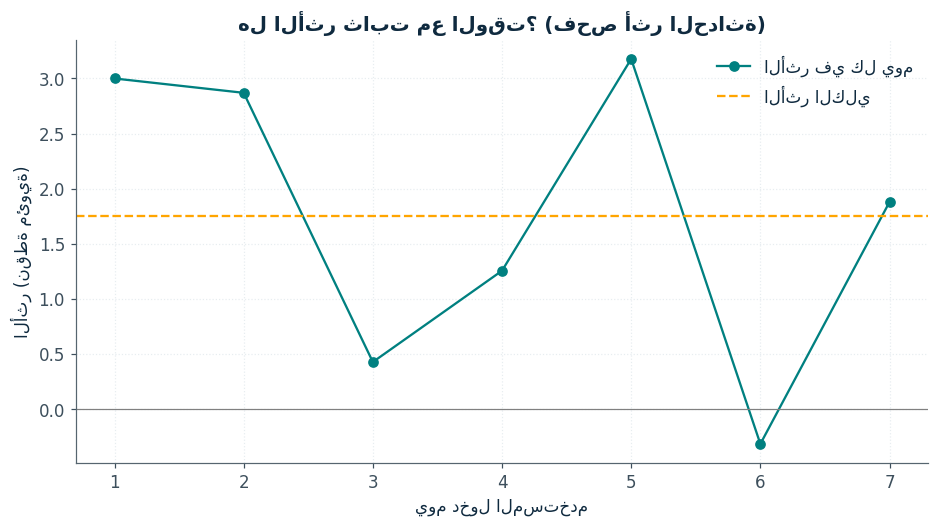

In [16]:
daily = data.groupby(["day", "variant"])["ordered"].mean().unstack()
daily_lift = (daily["B"] - daily["A"]) * 100

plt.figure(figsize=(10, 5))
plt.plot(daily_lift.index, daily_lift.values, marker="o", color="teal", label="الأثر في كل يوم")
plt.axhline(primary["الفرق"] * 100, color="orange", linestyle="--", label="الأثر الكلي")
plt.axhline(0, color="gray", linewidth=0.8)
plt.xlabel("يوم دخول المستخدم")
plt.ylabel("الأثر (نقطة مئوية)")
plt.title("هل الأثر ثابت مع الوقت؟ (فحص أثر الحداثة)")
plt.legend()
plt.grid(True, linestyle=":", alpha=0.6)
plt.show()

<div dir="rtl">

## 8. (اختياري) إذا لم تستطع إجراء تجربة: الفروق في الفروق

إذا كان مشروعك سياسة طُبقت في مناطق دون غيرها، فعدّل الإعدادات في الخلية التالية، وطبق خطوات اليوم الثالث نفسها.

</div>

In [7]:
import html
from IPython.display import HTML, display
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf

def say(*parts, sep=" "):
    text = html.escape(sep.join(str(p) for p in parts))
    display(HTML(f'<div dir="rtl" style="white-space: pre-wrap; line-height: 1.7;">{text}</div>'))

def simulate_policy_panel(n_units=20, n_treated=6, n_periods=24, policy_period=13, effect=8.0, seed=32):
    r = np.random.default_rng(seed)
    level = r.normal(100, 15, n_units)
    shock = r.normal(0, 2, n_periods)
    rows = []

    for i in range(n_units):
        for t in range(1, n_periods + 1):
            treated, post = int(i < n_treated), int(t >= policy_period)
            y = level[i] + 0.8 * t + shock[t - 1] + effect * treated * post + r.normal(0, 3)
            rows.append({"unit": i, "period": t, "treated": treated, "post": post, "y": y})

    df = pd.DataFrame(rows)
    df["treated_post"] = df["treated"] * df["post"]
    return df

policy = simulate_policy_panel()
twfe = smf.ols("y ~ treated_post + C(unit) + C(period)", data=policy).fit(
    cov_type="cluster", cov_kwds={"groups": policy["unit"]}
)

lo, hi = twfe.conf_int().loc["treated_post"]
say(f"📊 أثر السياسة (DiD): {twfe.params['treated_post']:.2f}، وفترة الثقة 95% من {lo:.2f} إلى {hi:.2f}")
display(twfe.summary().tables[1])

/usr/local/lib/python3.13/dist-packages/statsmodels/base/model.py:1988: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 43, but rank is 19
  res = self.wald_test(


,coef,std err,z,P>|z|,[0.025,0.975]
Intercept,117.4955,0.633,185.727,0.000,116.256,118.735
C(unit)[T.1],-2.3272,1.67e-14,-1.39e+14,0.000,-2.327,-2.327
C(unit)[T.2],-13.6870,9.27e-14,-1.48e+14,0.000,-13.687,-13.687
C(unit)[T.3],-3.1430,8.2e-14,-3.84e+13,0.000,-3.143,-3.143
C(unit)[T.4],-22.1424,3.06e-13,-7.24e+13,0.000,-22.142,-22.142
C(unit)[T.5],-40.2532,1.41e-13,-2.86e+14,0.000,-40.253,-40.253
C(unit)[T.6],12.8511,0.336,38.267,0.000,12.193,13.509
C(unit)[T.7],-5.7580,0.336,-17.145,0.000,-6.416,-5.100
C(unit)[T.8],-44.1950,0.336,-131.599,0.000,-44.853,-43.537
C(unit)[T.9],-30.1389,0.336,-89.744,0.000,-30.797,-29.481


<div dir="rtl">

## 9. التقرير والتوصية

الخلية التالية تنشئ تقرير الصفحة الواحدة من نتائج القسم 7. عدّل عدد المستخدمين السنوي حسب مشروعك.

</div>

In [18]:

annual_users = 2_000_000                 # عدد المستخدمين في السنة الذين يتأثرون بالقرار
guardrails_ok = all(s == "سليم" for s in guard_status.values())
decision = decide(primary["أدنى 95%"], primary["أعلى 95%"], CONFIG["mde_abs"], guardrails_ok)
profit = guard_table.loc["الربح لكل مستخدم"]
guard_rows = "\n".join(f"| {k} | {v} |" for k, v in guard_status.items())

report = f"""
<div dir="rtl">

### تقرير التجربة: {CONFIG['project']}

**القرار:** {decision}

| البند | القيمة |
|---|---|
| المقياس الرئيسي | نسبة الطلب من {A['ordered'].mean():.2%} إلى {B['ordered'].mean():.2%} |
| الأثر | {primary['الفرق'] * 100:.2f} نقطة (فترة الثقة 95%: من {primary['أدنى 95%'] * 100:.2f} إلى {primary['أعلى 95%'] * 100:.2f}) |
| الأثر مع CUPED | {primary_cuped['الفرق'] * 100:.2f} نقطة (من {primary_cuped['أدنى 95%'] * 100:.2f} إلى {primary_cuped['أعلى 95%'] * 100:.2f}) |
| التغير التقديري في الربح السنوي | {profit['الفرق'] * annual_users / 1e6:.2f} مليون ريال (من {profit['أدنى 95%'] * annual_users / 1e6:.2f} إلى {profit['أعلى 95%'] * annual_users / 1e6:.2f}) |

| مقياس الحماية | الحالة |
|---|---|
{guard_rows}

</div>
"""
display(Markdown(report))


<div dir="rtl">

### تقرير التجربة: منصة نقاء (Nugaa)

**القرار:** نطلق، لأن الأثر إيجابي بثقة ومقاييس الحماية سليمة.

| البند | القيمة |
|---|---|
| المقياس الرئيسي | نسبة الطلب من 11.47% إلى 13.22% |
| الأثر | 1.75 نقطة (فترة الثقة 95%: من 0.98 إلى 2.52) |
| الأثر مع CUPED | 1.87 نقطة (من 1.12 إلى 2.63) |
| التغير التقديري في الربح السنوي | 1.33 مليون ريال (من 0.72 إلى 1.93) |

| مقياس الحماية | الحالة |
|---|---|
| الربح لكل مستخدم | سليم |
| نسبة إلغاء الطلبات | سليم |
| التواصل مع الدعم | سليم |

</div>


<div dir="rtl">

**توصيتك النهائية والقيود** (من 3 إلى 5 أسطر):

</div>

<div dir="rtl">

* **التوصية:** الاعتماد النهائي لإطلاق واجهة التجربة (B) بنسبة 100% لمستخدمي منصة "نقاء" نظراً لتحقيقها زيادات دالة إحصائياً في معدل التحويل والربحية.
* **الخطوة التالية:** مراقبة الأداء التشغيلي بعد الإطلاق الكامل، ومتابعة مقاييس الحماية بصفة دورية لضمان استدامة الأثر الإيجابي.
* **القيود:** الاعتماد على بيانات محاكاة قصيرة الأمد (7 أيام)، مما يستوجب الحذر لاحقاً لاحتمالية وجود تأثير مؤقت للحداثة.

</div>